<img src="https://www.institutomillenium.org.br/wp-content/uploads/2024/02/logo-ibmec-topo-rj-450x150.png.webp" width=300>

# Programação para Análise de Dados

## Aula 2 — Classificação com K-Nearest Neighbors (KNN)

**Duração:** 1h50 · **Bibliotecas:** `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`

| Bloco | Tema | Tempo |
|---|---|---|
| 1 | Preparação do ambiente | 5 min |
| 2 | Dados sintéticos: laranjas e limões | 10 min |
| 3 | A ideia do KNN (conceito, sem código) | 10 min |
| 4 | KNN no scikit-learn, passo a passo | 30 min |
| 5 | Escala das variáveis (padronização) | 10 min |
| 6 | Escolhendo o K | 10 min |
| 7 | Datasets do scikit-learn: Iris e Breast Cancer | 25 min |
| 8 | Exercícios e fechamento | 10 min |

> **Como usar este notebook:** antes de cada bloco de código há uma explicação em texto e a lista **"Linha a linha"**. Dentro do código, cada linha também tem um comentário `# ...`. Execute as células **em ordem**, com `Shift + Enter`.

# 🧰 Bloco 1 — Preparação do ambiente (5 min)

**Classificar** é prever uma **categoria** (laranja ou limão, doente ou saudável), diferente da regressão (Aula 1), que prevê um **número**.

### Importando as bibliotecas

Rode a célula abaixo. Se aparecer "Ambiente pronto!", está tudo certo.

**🔍 Linha a linha**

- `import numpy as np`, `import pandas as pd`, `import matplotlib.pyplot as plt`, `import seaborn as sns`: carregam as bibliotecas de sempre, cada uma com um apelido curto.
- `KNeighborsClassifier`: o modelo KNN para classificação ("Neighbors" = vizinhos).
- `train_test_split`: separa os dados em treino e teste (como na Aula 1).
- `StandardScaler`: ferramenta que coloca variáveis na mesma escala (veremos no Bloco 5).
- `accuracy_score`, `confusion_matrix`, `precision_score`, `recall_score`: as métricas de classificação desta aula.
- `DecisionBoundaryDisplay`: ferramenta do scikit-learn que desenha, em um clique, as regiões que o modelo atribui a cada classe.
- `ListedColormap`: permite escolher as cores dessas regiões.
- As linhas finais configuram avisos, estilo e tamanho dos gráficos e guardam 4 cores.

In [1]:
import numpy as np                                    # numpy: contas com números e sorteios aleatórios
import pandas as pd                                   # pandas: tabelas de dados (DataFrame)
import matplotlib.pyplot as plt                       # matplotlib: gráficos
import seaborn as sns                                 # seaborn: gráficos estatísticos (heatmap)
from sklearn.neighbors import KNeighborsClassifier    # o classificador KNN
from sklearn.model_selection import train_test_split  # separa os dados em treino e teste
from sklearn.preprocessing import StandardScaler      # coloca as variáveis na mesma escala
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score   # métricas
from sklearn.inspection import DecisionBoundaryDisplay   # desenha a fronteira de decisão do modelo
from matplotlib.colors import ListedColormap          # cria uma paleta de cores própria
import warnings                                       # avisos do Python
warnings.filterwarnings('ignore')                     # esconde avisos para a saída ficar limpa

sns.set_theme(style='whitegrid')                      # estilo visual dos gráficos
plt.rcParams['figure.figsize'] = (7, 4.5)             # tamanho padrão dos gráficos

AZUL, OURO, VERM, CINZA = '#16273E', '#F4AC02', '#C0392B', '#8C8C8C'   # cores que usaremos
print('Ambiente pronto!')                             # mensagem de confirmação

Ambiente pronto!


# 🧪 Bloco 2 — Dados sintéticos: laranjas e limões (10 min)

Vamos criar frutas fictícias. Para cada fruta medimos **peso** (g) e **diâmetro** (cm), e queremos descobrir **se é laranja ou limão**.

| Fruta | Código | Peso médio | Diâmetro médio |
|---|---|---|---|
| Laranja | **0** | 150 g | 7,5 cm |
| Limão | **1** | 135 g | 6,0 cm |

O **diâmetro** separa bem as frutas; o **peso** quase não ajuda (as frutas variam muito de peso, e as médias são parecidas). Guarde essa informação: ela será importante no Bloco 5.

### Criando os dados

Sorteamos 50 laranjas e 50 limões e juntamos tudo em uma tabela.

**🔍 Linha a linha**

- `rng.normal(150, 40, n)`: sorteia `n` valores em forma de sino, com média 150 e desvio 40.
- `np.concatenate([a, b])`: cola duas listas uma depois da outra (primeiro as laranjas, depois os limões).
- `'fruta': [0] * n + [1] * n`: monta a coluna de **classes**: `n` zeros seguidos de `n` uns.
- `.map({0: 'Laranja', 1: 'Limão'})`: troca cada código pelo nome correspondente (só para deixar os gráficos legíveis).
- `df_frutas.sample(5)`: mostra 5 linhas aleatórias (assim vemos as duas frutas, não só as primeiras linhas).

In [2]:
rng = np.random.default_rng(42)                        # gerador aleatório; 42 = semente (resultados repetíveis)
n = 50                                                 # 50 frutas de cada tipo

peso_lar = rng.normal(150, 40, n)                      # pesos das laranjas: média 150, desvio 40
diam_lar = rng.normal(7.5, 0.6, n)                     # diâmetros das laranjas: média 7,5, desvio 0,6
peso_lim = rng.normal(135, 40, n)                      # pesos dos limões: média 135, desvio 40
diam_lim = rng.normal(6.0, 0.6, n)                     # diâmetros dos limões: média 6,0, desvio 0,6

df_frutas = pd.DataFrame({                             # monta a tabela juntando as duas frutas
    'peso_g': np.concatenate([peso_lar, peso_lim]).round(0),          # coluna do peso
    'diametro_cm': np.concatenate([diam_lar, diam_lim]).round(1),     # coluna do diâmetro
    'fruta': [0] * n + [1] * n                         # classe: 50 zeros (laranja) e 50 uns (limão)
})
df_frutas['nome'] = df_frutas['fruta'].map({0: 'Laranja', 1: 'Limão'})   # coluna extra com o nome, para os gráficos
df_frutas.sample(5, random_state=1)                    # mostra 5 linhas sorteadas

,peso_g,diametro_cm,fruta,nome
80,119.0,6.8,1,Limão
84,76.0,6.3,1,Limão
33,117.0,7.3,0,Laranja
81,80.0,6.1,1,Limão
93,146.0,6.9,1,Limão


### Olhando os dados

Cada ponto é uma fruta; a cor mostra a classe.

**🔍 Linha a linha**

- `for codigo, cor in [(0, OURO), (1, AZUL)]`: um **laço**: executa o bloco indentado duas vezes, uma para cada par (classe, cor).
- `df_frutas[df_frutas['fruta'] == codigo]`: **filtro**: mantém só as linhas em que a coluna `fruta` é igual ao código da vez.
- `parte['nome'].iloc[0]`: pega o nome (Laranja ou Limão) da primeira linha filtrada, para usar na legenda.
- O restante é o padrão dos gráficos: título, nomes dos eixos, legenda e `plt.show()`.

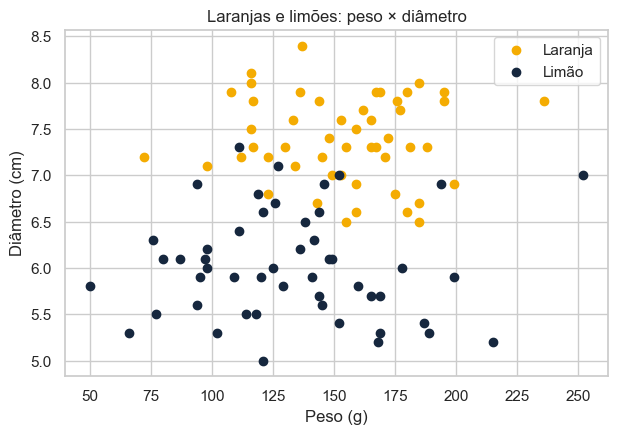

In [3]:
for codigo, cor in [(0, OURO), (1, AZUL)]:                          # repete para a classe 0 (laranja) e a 1 (limão)
    parte = df_frutas[df_frutas['fruta'] == codigo]                 # filtra só as frutas dessa classe
    plt.scatter(parte['peso_g'], parte['diametro_cm'],              # x = peso, y = diâmetro
                color=cor, label=parte['nome'].iloc[0])             # cor da classe e nome na legenda
plt.title('Laranjas e limões: peso × diâmetro')                     # título
plt.xlabel('Peso (g)')                                              # eixo x
plt.ylabel('Diâmetro (cm)')                                         # eixo y
plt.legend()                                                        # legenda
plt.show()                                                          # exibe

👀 **O que vemos:** as frutas se separam principalmente na **vertical** (diâmetro). No eixo do peso, as nuvens se sobrepõem bastante.

# 🧭 Bloco 3 — A ideia do KNN (10 min)

> **Analogia:** você chega a um bairro novo e quer saber se vai gostar de um restaurante. Pergunta a **K vizinhos** e segue a **maioria**. O KNN (*K-Nearest Neighbors*, "K vizinhos mais próximos") faz exatamente isso.

### O que o KNN faz, em 4 passos
1. Você escolhe **K** (quantos vizinhos consultar), por exemplo K = 5.
2. Para um caso novo, o modelo mede a **distância** até todos os casos conhecidos.
3. Separa os **K mais próximos**.
4. A classe prevista é a **mais frequente** entre esses K (**votação**).

> **Quem faz as contas?** O scikit-learn. Você **não** precisa programar distâncias nem votação: basta criar o modelo (`KNeighborsClassifier`), treinar (`fit`) e prever (`predict`). Seu trabalho é **preparar os dados**, **escolher K** e **interpretar os resultados**.

### Distância (só para entender o conceito)
A distância usada é a **euclidiana**, a "linha reta" entre dois pontos. Quanto **menor** a distância, mais **parecidos** são os casos.

### Dois pontos importantes
- O KNN **não aprende uma fórmula**: ele apenas **guarda** os dados e, na hora de prever, procura os vizinhos.
- Como tudo depende de distância, **a escala das variáveis importa** (Bloco 5).

No Bloco 4 você verá, no gráfico, quem são os vizinhos de uma fruta nova.

# 🛠️ Bloco 4 — KNN no scikit-learn, passo a passo (25 min)

Quem faz as contas é o scikit-learn: usamos o `KNeighborsClassifier`. Os passos são **quase os mesmos** da regressão (Aula 1):

| Passo | O que fazer | Código |
|---|---|---|
| 1 | Separar **X** (características) e **y** (classe) | `X = df[[...]]`, `y = df['classe']` |
| 2 | Dividir em treino e teste | `train_test_split(...)` |
| 3 | Criar o modelo, escolhendo K | `KNeighborsClassifier(n_neighbors=5)` |
| 4 | Treinar | `.fit(X_treino, y_treino)` |
| 5 | Prever | `.predict(X_teste)` |
| 6 | Avaliar | `accuracy_score(y_teste, y_prev)` |

> **Acurácia** = fração de acertos (acertos ÷ total). Acurácia 0,90 = o modelo acertou 90% dos casos do teste.

### Passos 1 a 6

Vamos treinar o KNN com **K = 5** para classificar as frutas.

**🔍 Linha a linha**

- `X = df_frutas[['peso_g', 'diametro_cm']]`: as colunas que o modelo usa para decidir (dois colchetes = tabela).
- `y = df_frutas['fruta']`: a coluna que queremos prever (a classe).
- `train_test_split(..., test_size=0.25, stratify=y)`: separa 25% para teste. **`stratify=y`** garante que treino e teste tenham a mesma proporção de laranjas e limões.
- `KNeighborsClassifier(n_neighbors=5)`: cria o modelo; `n_neighbors` é o **K**.
- `knn.fit(X_treino, y_treino)`: o KNN apenas **memoriza** os pontos de treino.
- `knn.predict(X_teste)`: para cada fruta do teste, acha os 5 vizinhos mais próximos no treino e vota.
- `accuracy_score(y_teste, y_prev)`: compara as classes reais com as previstas e devolve a fração de acertos.

In [4]:
X = df_frutas[['peso_g', 'diametro_cm']]               # passo 1: X = as duas características (colchetes duplos)
y = df_frutas['fruta']                                 # passo 1: y = a classe (0 laranja, 1 limão)

X_treino, X_teste, y_treino, y_teste = train_test_split(   # passo 2: divide em treino e teste
    X, y, test_size=0.25,                              # 25% dos dados vão para o teste
    random_state=42, stratify=y)                       # semente fixa; stratify=y mantém a mesma proporção de classes

knn = KNeighborsClassifier(n_neighbors=5)              # passo 3: cria o modelo com K = 5 vizinhos
knn.fit(X_treino, y_treino)                            # passo 4: "treina" (o KNN apenas guarda os dados de treino)
y_prev = knn.predict(X_teste)                          # passo 5: prevê a classe das frutas do teste

acuracia = accuracy_score(y_teste, y_prev)             # passo 6: fração de acertos
print(f'Acurácia no teste: {acuracia:.2f}')            # mostra a acurácia

Acurácia no teste: 0.64


### 🔍 Como interpretar a acurácia
- **Acurácia 0,90** = o modelo acertou 90% das frutas do teste (casos que ele **nunca viu** no treino).
- Compare sempre com um **palpite de referência**: com 2 classes equilibradas, chutar dá cerca de 0,50. Um modelo só é bom se **superar** essa referência com folga.
- Poucos casos no teste (aqui, 25) → o valor "balança" de uma divisão para outra. Use a acurácia como **indicação**, não como verdade exata.

### Classificando uma fruta nova

Uma fruta com 140 g e 6,8 cm. É laranja ou limão? E com que "confiança"?

**🔍 Linha a linha**

- `pd.DataFrame({'peso_g': [140], ...})`: a fruta nova deve ter **as mesmas colunas, com os mesmos nomes**, do treino.
- `knn.predict(...)[0]`: o resultado vem em uma lista; `[0]` pega o primeiro valor.
- `knn.predict_proba(...)`: devolve a **proporção de vizinhos** de cada classe. Com K = 5 e 4 vizinhos limão, seria 0,8 para limão.
- `nomes[classe]`: usa o código (0 ou 1) como posição na lista para obter o nome.

In [5]:
fruta_nova = pd.DataFrame({'peso_g': [140], 'diametro_cm': [6.8]})   # tabela com a fruta nova (mesmos nomes de coluna)
classe = knn.predict(fruta_nova)[0]                    # classe prevista (0 ou 1)
prob = knn.predict_proba(fruta_nova)[0]                # fração de vizinhos de cada classe
nomes = ['Laranja', 'Limão']                           # lista de nomes: posição 0 = laranja, 1 = limão

print('Fruta prevista:', nomes[classe])                # traduz o código para o nome
print(f'Proporção de vizinhos -> laranja: {prob[0]:.2f} | limão: {prob[1]:.2f}')   # votos em proporção

Fruta prevista: Limão
Proporção de vizinhos -> laranja: 0.20 | limão: 0.80


### Quem são os vizinhos?

O método `kneighbors` do modelo treinado mostra **quais** casos do treino foram consultados para a fruta nova.

**🔍 Linha a linha**

- `knn.kneighbors(fruta_nova)`: devolve duas listas: as **distâncias** e as **posições** (no treino) dos K vizinhos mais próximos.
- `X_treino.iloc[pos[0]]`: pega no treino as linhas que têm essas posições (`pos[0]` porque há uma só fruta nova).
- `vizinhos['classe'] = ...`: acrescenta colunas à tabela para ver, ao lado das medidas, a classe e a distância de cada vizinho.
- `facecolors='none'`: círculo vazio, usado para destacar os vizinhos sem esconder os pontos.
- **Como interpretar:** a classe prevista é a que domina entre esses 5 vizinhos, e `predict_proba` é apenas a proporção deles em cada classe.
- **Repare:** as distâncias da tabela são quase só a diferença de **peso** (a variável menos útil). O Bloco 5 mostra o porquê e como corrigir.

    peso_g  diametro_cm  classe  distancia
99   141.0          5.9       1        1.3
64   138.0          6.5       1        2.0
71   142.0          6.3       1        2.1
67   136.0          6.2       1        4.0
25   136.0          7.9       0        4.1


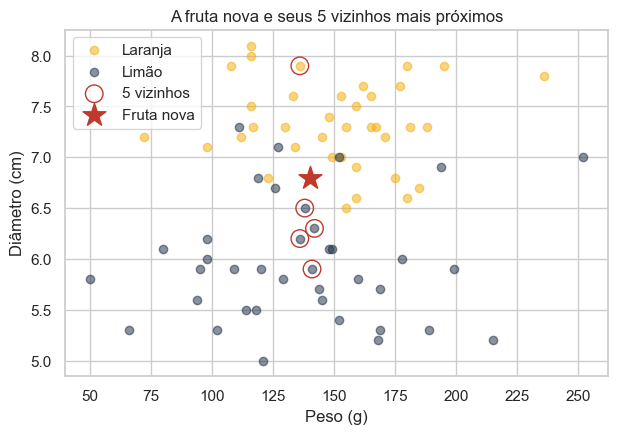

In [6]:
dist, pos = knn.kneighbors(fruta_nova)                 # distâncias e posições dos 5 vizinhos mais próximos
vizinhos = X_treino.iloc[pos[0]].copy()                # linhas do treino que são vizinhas da fruta nova
vizinhos['classe'] = y_treino.iloc[pos[0]].values      # acrescenta a classe de cada vizinho
vizinhos['distancia'] = dist[0].round(1)               # acrescenta a distância até a fruta nova
print(vizinhos.to_string())                            # mostra a tabela dos vizinhos

for codigo, cor in [(0, OURO), (1, AZUL)]:             # pontos de treino, uma classe por vez
    parte = X_treino[y_treino == codigo]               # frutas de treino dessa classe
    plt.scatter(parte['peso_g'], parte['diametro_cm'], color=cor, alpha=0.5, label=['Laranja', 'Limão'][codigo])
plt.scatter(vizinhos['peso_g'], vizinhos['diametro_cm'], s=160, facecolors='none',
            edgecolors=VERM, label='5 vizinhos')       # círculos vermelhos ao redor dos vizinhos
plt.scatter(140, 6.8, color=VERM, marker='*', s=300, label='Fruta nova')   # estrela = fruta nova
plt.title('A fruta nova e seus 5 vizinhos mais próximos')   # título
plt.xlabel('Peso (g)')                                 # eixo x
plt.ylabel('Diâmetro (cm)')                            # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

### Visualizando a fronteira de decisão

O `DecisionBoundaryDisplay` pinta o plano inteiro com a classe que o modelo preveria em cada ponto.

**🔍 Linha a linha**

- `ListedColormap([...])`: define as duas cores de fundo, uma para cada classe.
- `DecisionBoundaryDisplay.from_estimator(knn, X_treino, ...)`: o scikit-learn testa o modelo em milhares de pontos do gráfico e pinta cada região com a classe prevista.
- `X_treino[y_treino == codigo]`: filtra as frutas de treino da classe da vez, para desenhá-las por cima do fundo.
- O restante é o padrão dos gráficos: título, eixos, legenda e `plt.show()`.

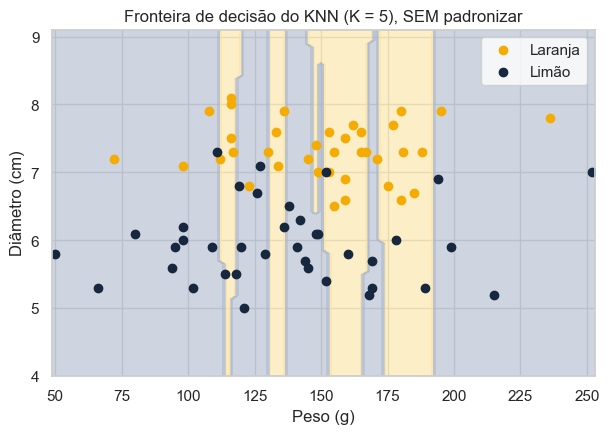

In [7]:
cores_fundo = ListedColormap(['#FBE3A0', '#AEB9CC'])    # amarelo claro = laranja; cinza-azulado = limão
DecisionBoundaryDisplay.from_estimator(knn, X_treino,   # desenha as regiões de decisão do modelo knn
                                       cmap=cores_fundo, alpha=0.6,   # cores e transparência
                                       response_method='predict')     # pinta pela classe prevista
for codigo, cor in [(0, OURO), (1, AZUL)]:             # desenha os pontos de treino por classe
    parte = X_treino[y_treino == codigo]               # frutas de treino dessa classe
    plt.scatter(parte['peso_g'], parte['diametro_cm'], color=cor, label=['Laranja', 'Limão'][codigo])   # pontos
plt.title('Fronteira de decisão do KNN (K = 5), SEM padronizar')   # título
plt.xlabel('Peso (g)')                                 # eixo x
plt.ylabel('Diâmetro (cm)')                            # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

👀 **Repare:** as fronteiras são quase **verticais**, ou seja, o modelo está decidindo principalmente pelo **peso**, que é justamente a variável **menos útil**! Por quê? Veja o próximo bloco.

# ⚖️ Bloco 5 — Escala das variáveis: padronização (10 min)

O KNN decide por **distâncias**. Compare:

- o peso varia **dezenas de gramas** (ex.: de 100 a 180);
- o diâmetro varia **poucos centímetros** (ex.: de 5 a 8).

Na conta da distância, uma diferença de 20 g **pesa mais** que uma diferença de 2 cm, mesmo que o diâmetro seja a variável importante. A variável de **maior escala domina**.

### Solução: padronizar
Transformamos cada variável para ter **média 0** e **desvio-padrão 1**:

$$z = \frac{x - \text{média}}{\text{desvio-padrão}}$$

Assim todas passam a contar de forma comparável.

> ⚠️ **Regra de ouro:** a média e o desvio são calculados **só com o treino** (`fit_transform`). No teste usamos os mesmos valores (`transform`). Se o teste participasse do cálculo, estaríamos "espiando a prova".

### Padronizando e comparando

Treinamos o mesmo KNN com dados padronizados e comparamos a acurácia.

**🔍 Linha a linha**

- `StandardScaler()`: cria a ferramenta que padroniza.
- `scaler.fit_transform(X_treino)`: **fit** = calcula média e desvio de cada coluna do treino; **transform** = aplica a fórmula z. Faz as duas coisas de uma vez.
- `scaler.transform(X_teste)`: só aplica a fórmula, com a média e o desvio **do treino**.
- O resto é igual ao Bloco 4: criar o KNN, `fit`, `predict` e comparar as acurácias.
- **Resultado:** a acurácia sobe, porque agora o diâmetro (variável útil) tem peso justo na distância.

In [8]:
scaler = StandardScaler()                              # cria o padronizador
X_treino_pad = scaler.fit_transform(X_treino)          # aprende média e desvio do TREINO e já padroniza o treino
X_teste_pad = scaler.transform(X_teste)                # padroniza o TESTE com a média e o desvio do treino

knn_pad = KNeighborsClassifier(n_neighbors=5)          # novo KNN, também com K = 5
knn_pad.fit(X_treino_pad, y_treino)                    # treina com os dados padronizados
y_prev_pad = knn_pad.predict(X_teste_pad)              # prevê no teste padronizado

print(f'Acurácia SEM padronizar: {accuracy_score(y_teste, y_prev):.2f}')       # resultado anterior
print(f'Acurácia COM padronizar: {accuracy_score(y_teste, y_prev_pad):.2f}')   # resultado novo

Acurácia SEM padronizar: 0.64
Acurácia COM padronizar: 0.88


### A nova fronteira

Agora as regiões devem se separar principalmente na **horizontal** (pelo diâmetro).

**🔍 Linha a linha**

- Mesma ferramenta do gráfico anterior, agora com o modelo `knn_pad` e os dados **padronizados** (eixos em torno de −3 a 3).
- `X_treino_pad[..., 0]`: o resultado do `StandardScaler` é uma tabela numérica (sem nomes); a coluna 0 é o peso e a 1 é o diâmetro.
- **Como interpretar:** compare com o gráfico anterior. A fronteira girou: agora o diâmetro (variável útil) comanda a decisão.

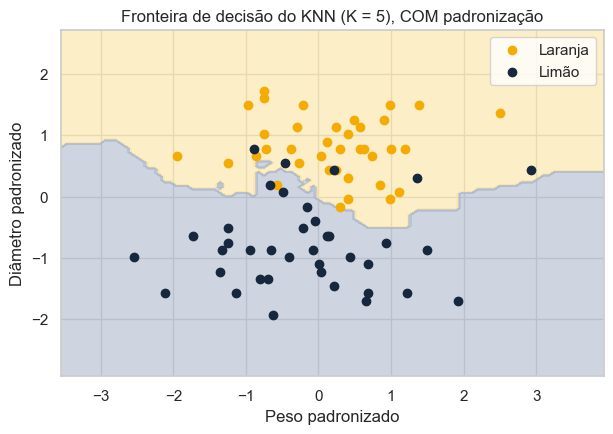

In [9]:
DecisionBoundaryDisplay.from_estimator(knn_pad, X_treino_pad,   # regiões de decisão do modelo padronizado
                                       cmap=cores_fundo, alpha=0.6, response_method='predict')   # mesmas cores de antes
for codigo, cor in [(0, OURO), (1, AZUL)]:             # pontos de treino por classe
    plt.scatter(X_treino_pad[y_treino.values == codigo, 0],     # x padronizado (peso)
                X_treino_pad[y_treino.values == codigo, 1],     # y padronizado (diâmetro)
                color=cor, label=['Laranja', 'Limão'][codigo])  # cor e legenda
plt.title('Fronteira de decisão do KNN (K = 5), COM padronização')   # título
plt.xlabel('Peso padronizado')                         # eixo x
plt.ylabel('Diâmetro padronizado')                     # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

# 🎯 Exercício 1 (5 min) — Fruta nova com o modelo padronizado

**Desafio:** classifique uma fruta com **130 g** e **6,5 cm** usando o `knn_pad`. Atenção: a fruta nova também precisa ser **padronizada** com o mesmo `scaler`!

In [10]:
# TODO: crie o DataFrame da fruta nova, padronize com scaler.transform(...) e use knn_pad.predict(...)

# 🎚️ Bloco 6 — Escolhendo o K (10 min)

O valor de **K** muda o resultado:

- **K pequeno (1, 2)**: o modelo "decora" cada ponto, inclusive o ruído → vai bem no treino, **pior em dados novos** (*overfitting*).
- **K grande (30, 40)**: olha vizinhos demais e "borra" os detalhes → **erra mais** (*underfitting*).

Para escolher, testamos vários valores de K e **olhamos o gráfico**.

### Acurácia para cada valor de K

Treinamos um KNN para cada K de 1 a 25 e guardamos a acurácia no treino e no teste.

**🔍 Linha a linha**

- `range(1, 26)`: sequência de 1 a 25 (o 26 não entra).
- `acc_treino = []`: cria uma lista vazia; o `append` vai acrescentando um valor a cada volta do laço.
- `for k in valores_k:` o bloco indentado roda uma vez para cada K.
- `modelo_k.score(X, y)`: atalho que devolve a **acurácia** do modelo naquele conjunto.
- `plt.plot(x, y, marker='o')`: desenha uma linha com bolinhas nos pontos.

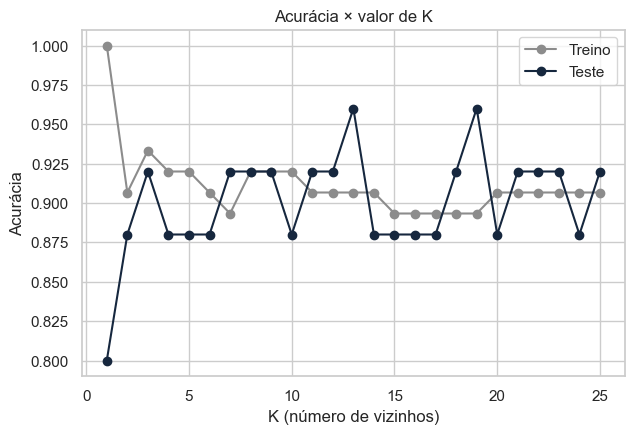

In [11]:
valores_k = range(1, 26)                               # K de 1 até 25
acc_treino = []                                        # lista vazia para guardar a acurácia no treino
acc_teste = []                                         # lista vazia para guardar a acurácia no teste

for k in valores_k:                                    # repete para cada K
    modelo_k = KNeighborsClassifier(n_neighbors=k)     # cria o KNN com esse K
    modelo_k.fit(X_treino_pad, y_treino)               # treina
    acc_treino.append(modelo_k.score(X_treino_pad, y_treino))   # acurácia no treino
    acc_teste.append(modelo_k.score(X_teste_pad, y_teste))      # acurácia no teste

plt.plot(valores_k, acc_treino, color=CINZA, marker='o', label='Treino')   # curva do treino
plt.plot(valores_k, acc_teste, color=AZUL, marker='o', label='Teste')      # curva do teste
plt.title('Acurácia × valor de K')                     # título
plt.xlabel('K (número de vizinhos)')                   # eixo x
plt.ylabel('Acurácia')                                 # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

👀 **Como ler:** com K = 1 a acurácia no **treino** é 1,0 (cada ponto é vizinho de si mesmo!), mas no teste ela é menor. Procure um K em que a curva do **teste** seja alta e estável. Como o teste tem poucas frutas, a curva "treme": **não existe K perfeito**, escolha um valor razoável (K ímpar em geral, para evitar empates).

# 🎯 Exercício 2 (5 min) — Melhor K

**Desafio:** com as listas `acc_teste` e `valores_k`, descubra o **K com maior acurácia no teste** e qual é essa acurácia.

In [12]:
# TODO: use np.argmax(acc_teste) para achar a posição do maior valor

# 🌸 Bloco 7 — Datasets do scikit-learn: Iris e Breast Cancer (25 min)

Agora vamos aplicar **os mesmos passos** a dois datasets reais já incluídos no scikit-learn.

## Dataset 1: Iris (3 classes)
150 flores de **3 espécies** (setosa, versicolor, virginica), com 4 medidas em cm: comprimento e largura da **sépala** e da **pétala**. Objetivo: descobrir a **espécie** pelas medidas.

### Carregando o Iris

O dataset já vem pronto; basta chamar a função.

**🔍 Linha a linha**

- `load_iris(as_frame=True)`: carrega o dataset como tabela.
- `iris.frame`: a tabela com as medidas e a coluna `target` (0, 1 ou 2 = espécie).
- `iris.target_names`: os nomes das espécies, na ordem dos códigos.
- `.value_counts().sort_index()`: conta as flores de cada classe (50 de cada: dataset **balanceado**).

In [13]:
from sklearn.datasets import load_iris                 # função que carrega o Iris

iris = load_iris(as_frame=True)                        # carrega já como tabela do pandas
df_iris = iris.frame                                   # tabela completa (4 medidas + 'target')
especies = [str(e) for e in iris.target_names]         # nomes das espécies (como texto): posição 0, 1, 2

print('Linhas e colunas:', df_iris.shape)              # formato da tabela
print('Espécies:', especies)                           # nomes das classes
print(df_iris['target'].value_counts().sort_index().to_string())   # quantas flores de cada classe
df_iris.head()                                         # primeiras linhas

Linhas e colunas: (150, 5)
Espécies: ['setosa', 'versicolor', 'virginica']
target
0    50
1    50
2    50


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### Olhando os dados

Duas medidas da pétala já separam bem as espécies.

**🔍 Linha a linha**

- Mesma estrutura do gráfico das frutas, agora com **3 espécies**.
- `cores_especies[codigo]` e `especies[codigo]`: usam o código (0, 1, 2) como posição para escolher a cor e o nome.
- A setosa fica isolada; versicolor e virginica ficam vizinhas, com alguma sobreposição.

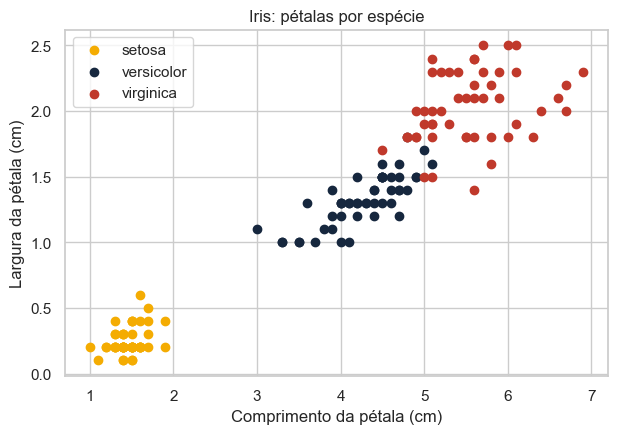

In [14]:
cores_especies = [OURO, AZUL, VERM]                    # uma cor para cada espécie
for codigo in [0, 1, 2]:                               # para cada espécie
    parte = df_iris[df_iris['target'] == codigo]       # filtra as flores dessa espécie
    plt.scatter(parte['petal length (cm)'], parte['petal width (cm)'],   # x = comprimento, y = largura da pétala
                color=cores_especies[codigo], label=especies[codigo])    # cor e nome na legenda
plt.title('Iris: pétalas por espécie')                 # título
plt.xlabel('Comprimento da pétala (cm)')               # eixo x
plt.ylabel('Largura da pétala (cm)')                   # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

### KNN no Iris

Os mesmos passos: separar, padronizar, treinar, prever e avaliar.

**🔍 Linha a linha**

- `df_iris.drop(columns='target')`: tabela sem a coluna `target`; vira X.
- Todo o resto repete o Bloco 5: `train_test_split` (com `stratify`), `StandardScaler`, `KNeighborsClassifier`, `fit`, `predict`, `accuracy_score`.
- Nomes com `i` no final (`Xi`, `yi`, `knn_iris`) evitam sobrescrever as variáveis das frutas.

In [15]:
Xi = df_iris.drop(columns='target')                    # X = as 4 medidas (todas as colunas menos o 'target')
yi = df_iris['target']                                 # y = a espécie (0, 1 ou 2)

Xi_treino, Xi_teste, yi_treino, yi_teste = train_test_split(   # divide treino e teste
    Xi, yi, test_size=0.25, random_state=42, stratify=yi)      # 25% teste; mesma proporção de espécies

scaler_i = StandardScaler()                            # padronizador
Xi_treino_pad = scaler_i.fit_transform(Xi_treino)      # aprende no treino e padroniza o treino
Xi_teste_pad = scaler_i.transform(Xi_teste)            # padroniza o teste com os valores do treino

knn_iris = KNeighborsClassifier(n_neighbors=5)         # KNN com K = 5
knn_iris.fit(Xi_treino_pad, yi_treino)                 # treina
yi_prev = knn_iris.predict(Xi_teste_pad)               # prevê as espécies do teste

print(f'Acurácia no teste: {accuracy_score(yi_teste, yi_prev):.2f}')   # fração de acertos

Acurácia no teste: 0.92


### Matriz de confusão

A acurácia diz **quanto** acertamos, mas não **onde** erramos. A **matriz de confusão** mostra, para cada classe **real** (linhas), quantas vezes o modelo previu cada classe (colunas).

- A **diagonal** (de cima à esquerda para baixo à direita) são os **acertos**.
- Fora da diagonal, os **erros**: a célula (versicolor, virginica) conta flores versicolor que o modelo chamou de virginica.

### Desenhando a matriz de confusão

Um heatmap com os números dentro de cada célula.

**🔍 Linha a linha**

- `confusion_matrix(y_real, y_previsto)`: conta os pares (classe real, classe prevista).
- `fmt='d'`: mostra os números como inteiros (sem casas decimais).
- `xticklabels=especies, yticklabels=especies`: troca os códigos 0, 1, 2 pelos nomes.
- Diagonal forte = poucos erros. Os erros costumam ocorrer entre as espécies vizinhas (versicolor e virginica).

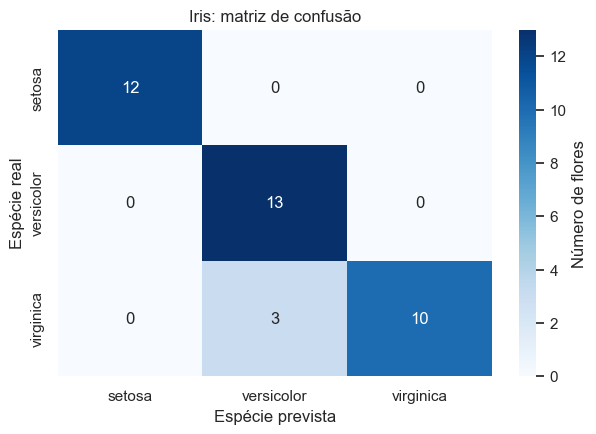

In [16]:
cm_iris = confusion_matrix(yi_teste, yi_prev)          # matriz: linhas = classe real, colunas = classe prevista
sns.heatmap(cm_iris, annot=True, fmt='d', cmap='Blues',   # annot=True escreve os números; fmt='d' = inteiros
            xticklabels=especies, yticklabels=especies,   # nomes das espécies nos eixos
            cbar_kws={'label': 'Número de flores'})       # título da barra de cores
plt.title('Iris: matriz de confusão')                  # título
plt.xlabel('Espécie prevista')                         # eixo x
plt.ylabel('Espécie real')                             # eixo y
plt.show()                                             # exibe

## Dataset 2: Breast Cancer (2 classes, 30 variáveis)

569 exames de tumores de mama. Cada tumor tem **30 medidas** (raio, textura, área, etc.). A classe é:

| Código | Significado |
|---|---|
| **0** | **maligno** (câncer) |
| **1** | **benigno** |

> Atenção ao código: aqui o **0 é o maligno**, a classe mais importante de detectar.

### Métricas para duas classes: precisão e recall
Trate "maligno" como a classe de interesse (o "positivo"):

| Palavra | Quer dizer |
|---|---|
| **VP** (verdadeiro positivo) | era maligno e o modelo disse maligno ✅ |
| **FP** (falso positivo) | era benigno e o modelo disse maligno (alarme falso) |
| **FN** (falso negativo) | era maligno e o modelo disse benigno ❌ (o erro **mais grave**) |
| **VN** (verdadeiro negativo) | era benigno e o modelo disse benigno ✅ |

- **Precisão** = VP ÷ (VP + FP): *dos que o modelo chamou de malignos, quantos eram?*
- **Recall** = VP ÷ (VP + FN): *dos malignos reais, quantos o modelo encontrou?*

> **Analogia:** um detector de fumaça. **Recall alto** = quase nenhum incêndio passa despercebido. **Precisão alta** = quase nenhum alarme é falso. Em saúde, queremos **recall alto**.

### Carregando o Breast Cancer

Mesma função, outro dataset.

**🔍 Linha a linha**

- `load_breast_cancer(as_frame=True)`: carrega o dataset como tabela do pandas.
- `.value_counts()`: mostra quantos exames há de cada classe (212 malignos e 357 benignos: um pouco **desbalanceado**).

In [17]:
from sklearn.datasets import load_breast_cancer       # função que carrega o dataset

cancer = load_breast_cancer(as_frame=True)             # carrega como tabela
df_cancer = cancer.frame                               # tabela completa (30 medidas + 'target')

print('Linhas e colunas:', df_cancer.shape)            # formato
print('Classes (0 = maligno, 1 = benigno):')           # lembrete dos códigos
print(df_cancer['target'].value_counts().sort_index().to_string())   # quantidade de cada classe

Linhas e colunas: (569, 31)
Classes (0 = maligno, 1 = benigno):
target
0    212
1    357


### KNN no Breast Cancer

Os mesmos passos. Compararemos com e sem padronização.

**🔍 Linha a linha**

- Com 30 variáveis em escalas muito diferentes (por exemplo, área em centenas e suavidade em centésimos), a padronização faz **grande diferença**.
- `modelo.score(X_teste, y_teste)`: atalho para a acurácia, sem chamar `predict` e `accuracy_score` separadamente.
- O restante repete os passos já vistos.

In [18]:
Xc = df_cancer.drop(columns='target')                  # X = as 30 medidas
yc = df_cancer['target']                               # y = 0 (maligno) ou 1 (benigno)

Xc_treino, Xc_teste, yc_treino, yc_teste = train_test_split(   # divide treino e teste
    Xc, yc, test_size=0.25, random_state=42, stratify=yc)      # mantém a proporção de classes

knn_sem = KNeighborsClassifier(n_neighbors=5)          # KNN para os dados SEM padronizar
knn_sem.fit(Xc_treino, yc_treino)                      # treina
acc_sem = knn_sem.score(Xc_teste, yc_teste)            # acurácia no teste, sem padronizar

scaler_c = StandardScaler()                            # padronizador
Xc_treino_pad = scaler_c.fit_transform(Xc_treino)      # aprende no treino e padroniza o treino
Xc_teste_pad = scaler_c.transform(Xc_teste)            # padroniza o teste

knn_c = KNeighborsClassifier(n_neighbors=5)            # KNN para os dados padronizados
knn_c.fit(Xc_treino_pad, yc_treino)                    # treina
yc_prev = knn_c.predict(Xc_teste_pad)                  # prevê no teste

print(f'Acurácia SEM padronizar: {acc_sem:.3f}')                      # resultado sem padronizar
print(f'Acurácia COM padronizar: {accuracy_score(yc_teste, yc_prev):.3f}')   # resultado com padronização

Acurácia SEM padronizar: 0.930
Acurácia COM padronizar: 0.979


### Matriz de confusão, precisão e recall

Usamos `pos_label=0` para dizer que a classe de interesse é o **maligno** (código 0).

**🔍 Linha a linha**

- `confusion_matrix(...)`: aqui a linha de cima é a classe real **0 (maligno)**; a célula (maligno, benigno) são os **falsos negativos**.
- `precision_score(..., pos_label=0)`: **`pos_label`** informa qual classe é a "positiva" (a de interesse). Sem isso, o scikit-learn assume a classe 1.
- `recall_score(..., pos_label=0)`: fração dos tumores malignos reais que o modelo encontrou.

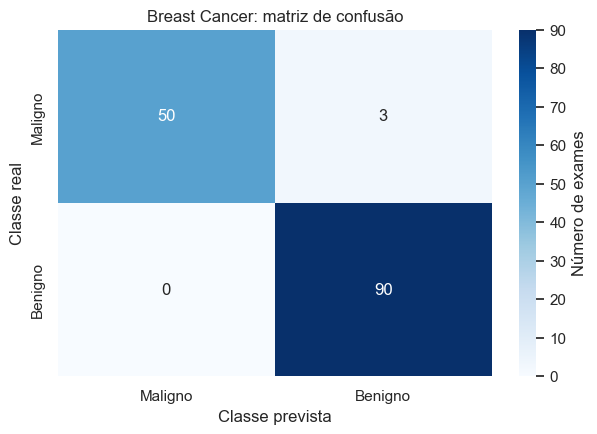

Precisão (maligno): 1.00
Recall   (maligno): 0.94


In [19]:
cm_c = confusion_matrix(yc_teste, yc_prev)             # matriz de confusão
nomes_c = ['Maligno', 'Benigno']                       # nomes das classes (posição 0 e 1)
sns.heatmap(cm_c, annot=True, fmt='d', cmap='Blues',   # heatmap com os números
            xticklabels=nomes_c, yticklabels=nomes_c,  # nomes nos eixos
            cbar_kws={'label': 'Número de exames'})    # legenda da barra
plt.title('Breast Cancer: matriz de confusão')         # título
plt.xlabel('Classe prevista')                          # eixo x
plt.ylabel('Classe real')                              # eixo y
plt.show()                                             # exibe

precisao = precision_score(yc_teste, yc_prev, pos_label=0)   # dos que chamei de maligno, quantos eram
recall = recall_score(yc_teste, yc_prev, pos_label=0)        # dos malignos reais, quantos encontrei
print(f'Precisão (maligno): {precisao:.2f}')           # mostra a precisão
print(f'Recall   (maligno): {recall:.2f}')             # mostra o recall

# 🎯 Exercício 3 (5 min) — K no Iris

**Desafio:** treine o KNN do Iris com **K = 1** e com **K = 15** (use `Xi_treino_pad`, `Xi_teste_pad`, `yi_treino`, `yi_teste`) e compare as acurácias no teste.

In [20]:
# TODO: crie dois KNN (n_neighbors=1 e n_neighbors=15), treine e compare o .score no teste

# 🎯 Exercício 4 (5 min) — Quantos tumores malignos passaram despercebidos?

**Desafio:** na matriz `cm_c`, quantos tumores **malignos** o modelo classificou como **benignos** (falsos negativos)? Qual o **recall** do maligno?

In [21]:
# TODO: o valor está na linha 0 (maligno real), coluna 1 (previsto benigno) de cm_c

# 🏁 Bloco 8 — Fechamento (10 min)

## Resumo da aula

| Conceito | Em uma frase |
|---|---|
| **KNN** | classifica um caso novo pela **votação dos K vizinhos mais próximos** |
| **Distância** | quão "longe" estão dois pontos (euclidiana = linha reta) |
| **K** | número de vizinhos: pequeno demais decora, grande demais borra |
| **Padronização** | coloca as variáveis na mesma escala (essencial no KNN) |
| **Acurácia** | fração de acertos |
| **Matriz de confusão** | mostra onde o modelo acerta e erra |
| **Precisão / Recall** | alarmes falsos × casos perdidos |

## Receita dos passos (vale para qualquer classificação com KNN)

```python
X = df[colunas]                                    # 1. separar X e y
y = df['classe']
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)   # 2. dividir
scaler = StandardScaler()                          # 3. padronizar (aprende no treino)
X_treino_pad = scaler.fit_transform(X_treino)
X_teste_pad = scaler.transform(X_teste)
knn = KNeighborsClassifier(n_neighbors=5)          # 4. criar o modelo
knn.fit(X_treino_pad, y_treino)                    # 5. treinar
y_prev = knn.predict(X_teste_pad)                  # 6. prever
print(accuracy_score(y_teste, y_prev))             # 7. avaliar
```

## Limitações do KNN
- Fica **lento** com muitos dados (mede a distância até todos os pontos).
- Com **muitas variáveis**, a ideia de "perto" perde sentido (a Aula 3 mostra como reduzir variáveis com PCA).
- **Sempre** padronize as variáveis.

## 📝 Tarefa para casa
Carregue o dataset **Wine** (`from sklearn.datasets import load_wine`) e aplique a receita acima. Escreva 3 linhas com a acurácia e o K que você escolheu.

# ✅ Gabarito dos exercícios

Respostas de todos os exercícios deste notebook. **Tente resolver antes de olhar!**

> As soluções abaixo são texto (não executam): copie o código para uma célula se quiser rodar.

## 🎯 Exercício 1 (5 min) — Fruta nova com o modelo padronizado

**Resposta (saída esperada):**

```text
Fruta prevista: Limão
```

**Código da solução:**

```python
fruta2 = pd.DataFrame({'peso_g': [130], 'diametro_cm': [6.5]})   # fruta nova
fruta2_pad = scaler.transform(fruta2)                  # padroniza com a média e o desvio do treino
classe2 = knn_pad.predict(fruta2_pad)[0]               # prevê
print('Fruta prevista:', ['Laranja', 'Limão'][classe2])   # traduz o código
```

## 🎯 Exercício 2 (5 min) — Melhor K

**Resposta (saída esperada):**

```text
Melhor K: 13 | acurácia no teste: 0.96
```

**Código da solução:**

```python
posicao = np.argmax(acc_teste)                         # posição do maior valor da lista
melhor_k = list(valores_k)[posicao]                    # K que corresponde a essa posição
print(f'Melhor K: {melhor_k} | acurácia no teste: {acc_teste[posicao]:.2f}')   # resultado
```

## 🎯 Exercício 3 (5 min) — K no Iris

**Resposta (saída esperada):**

```text
K = 1: acurácia no teste = 0.947
K = 15: acurácia no teste = 0.974
```

**Código da solução:**

```python
for k_ex in [1, 15]:                                    # testa os dois K
    modelo_ex = KNeighborsClassifier(n_neighbors=k_ex)  # cria o KNN
    modelo_ex.fit(Xi_treino_pad, yi_treino)             # treina
    print(f'K = {k_ex}: acurácia no teste = {modelo_ex.score(Xi_teste_pad, yi_teste):.3f}')   # resultado
```

## 🎯 Exercício 4 (5 min) — Quantos tumores malignos passaram despercebidos?

**Resposta (saída esperada):**

```text
Malignos classificados como benignos: 3
Recall do maligno: 0.94
```

**Código da solução:**

```python
falsos_negativos = cm_c[0, 1]                           # linha 0 = maligno real; coluna 1 = previsto benigno
print('Malignos classificados como benignos:', falsos_negativos)   # número de falsos negativos
print(f'Recall do maligno: {recall_score(yc_teste, yc_prev, pos_label=0):.2f}')   # recall
```